KHÁM PHÁ DỮ LIỆU

- Đọc file

In [2]:
import pandas as pd

df = pd.read_csv(r"C:\Users\hauth\OneDrive\Tài liệu\GitHub\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\BÀI TẬP NHÓM HẰNG TUẦN\LAB5 BÀI TOÁN PHÂN LỚP (NHÓM)\THUẬT TOÁN PHÂN LỚP\2.3.4 Naive mushroom\data\mushrooms.csv")

print(df.head())
print(df.shape)

  class cap-shape cap-surface cap-color bruises odor gill-attachment  \
0     p         x           s         n       t    p               f   
1     e         x           s         y       t    a               f   
2     e         b           s         w       t    l               f   
3     p         x           y         w       t    p               f   
4     e         x           s         g       f    n               f   

  gill-spacing gill-size gill-color  ... stalk-surface-below-ring  \
0            c         n          k  ...                        s   
1            c         b          k  ...                        s   
2            c         b          n  ...                        s   
3            c         n          n  ...                        s   
4            w         b          k  ...                        s   

  stalk-color-above-ring stalk-color-below-ring veil-type veil-color  \
0                      w                      w         p          w   
1       

- Cấu trúc dữ liệu

In [3]:
print(f"Kích thước dataset: {df.shape[0]} dòng × {df.shape[1]} cột\n")

print("Tên các cột:")
print(df.columns.tolist())

print("\nKiểu dữ liệu và số giá trị không thiếu:")
df.info()

print("\n5 dòng đầu:")
display(df.head())

Kích thước dataset: 8124 dòng × 23 cột

Tên các cột:
['class', 'cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor', 'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color', 'stalk-shape', 'stalk-root', 'stalk-surface-above-ring', 'stalk-surface-below-ring', 'stalk-color-above-ring', 'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number', 'ring-type', 'spore-print-color', 'population', 'habitat']

Kiểu dữ liệu và số giá trị không thiếu:
<class 'pandas.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   class                     8124 non-null   str  
 1   cap-shape                 8124 non-null   str  
 2   cap-surface               8124 non-null   str  
 3   cap-color                 8124 non-null   str  
 4   bruises                   8124 non-null   str  
 5   odor                      8124 non-null   str  
 6   gill-attach

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


- Thống kê mô tả

In [5]:
cot_thong_ke = ["count", "mean", "median", "std", "min", "25%", "75%", "max"]
df_so = df.select_dtypes(include="number")

if df_so.empty:
    print("Dataset không có cột số để tính các thống kê yêu cầu.")
    display(thong_ke)  # count, unique, top, freq cho các cột phân loại
else:
    display(df_so.describe().T.reindex(columns=cot_thong_ke))

Dataset không có cột số để tính các thống kê yêu cầu.


,count,unique,top,freq
class,8124,2,e,4208
cap-shape,8124,6,x,3656
cap-surface,8124,4,y,3244
cap-color,8124,10,n,2284
bruises,8124,2,f,4748
odor,8124,9,n,3528
gill-attachment,8124,2,f,7914
gill-spacing,8124,2,c,6812
gill-size,8124,2,b,5612
gill-color,8124,12,b,1728


- Chất lượng dữ liệu

In [6]:
# Kiểm tra giá trị thiếu thật sự và giá trị thiếu được mã hóa bằng "?"
so_lieu_chat_luong = pd.DataFrame({
    "Giá trị thiếu (NaN)": df.isna().sum(),
    "Giá trị '?'": df.astype("string").eq("?").sum(),
    "Số giá trị duy nhất": df.nunique(dropna=False)
})

display(so_lieu_chat_luong)

so_dong_trung = df.duplicated().sum()
cot_hang_so = df.columns[df.nunique(dropna=False) == 1].tolist()

print(f"Số dòng: {len(df):,}")
print(f"Số cột: {df.shape[1]}")
print(f"Số dòng trùng lặp: {so_dong_trung:,}")
print(f"Cột chỉ có một giá trị: {cot_hang_so or 'Không có'}")

if "class" in df.columns:
    print("\nPhân bố nhãn class:")
    display(df["class"].value_counts().to_frame("Số lượng"))

,Giá trị thiếu (NaN),Giá trị '?',Số giá trị duy nhất
class,0,0,2
cap-shape,0,0,6
cap-surface,0,0,4
cap-color,0,0,10
bruises,0,0,2
odor,0,0,9
gill-attachment,0,0,2
gill-spacing,0,0,2
gill-size,0,0,2
gill-color,0,0,12


Số dòng: 8,124
Số cột: 23
Số dòng trùng lặp: 0
Cột chỉ có một giá trị: ['veil-type']

Phân bố nhãn class:


,Số lượng
class,
e,4208
p,3916


- Phân tích nhãn mục tiêu

,Số mẫu,Tỷ lệ (%)
class,,
Ăn được (e),4208,51.8
Độc (p),3916,48.2


C:\Users\hauth\AppData\Local\Temp\ipykernel_18920\921616066.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set(


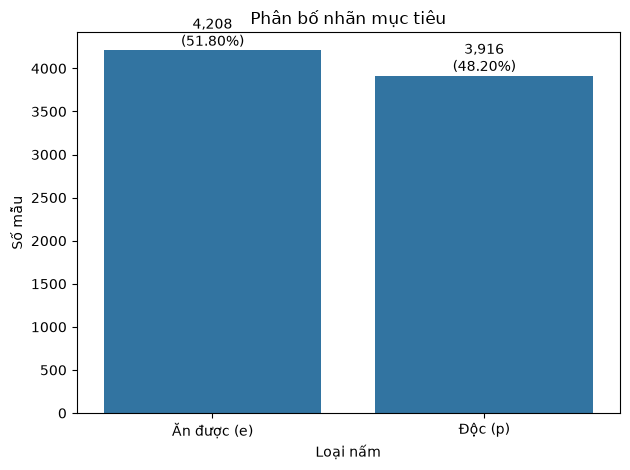

In [8]:
import seaborn as sns

counts = df["class"].value_counts().reindex(["e", "p"], fill_value=0)
percentages = counts / len(df) * 100

ket_qua_nhan = pd.DataFrame({
    "Số mẫu": counts,
    "Tỷ lệ (%)": percentages.round(2)
}).rename(index={"e": "Ăn được (e)", "p": "Độc (p)"})

display(ket_qua_nhan)

import matplotlib.pyplot as plt
ax = sns.countplot(data=df, x="class", order=["e", "p"])
ax.set(
    title="Phân bố nhãn mục tiêu",
    xlabel="Loại nấm",
    ylabel="Số mẫu",
    xticklabels=["Ăn được (e)", "Độc (p)"]
)

for bar, count, percent in zip(ax.patches, counts, percentages):
    ax.annotate(
        f"{count:,}\n({percent:.2f}%)",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

- Phân tích từng thuộc tính

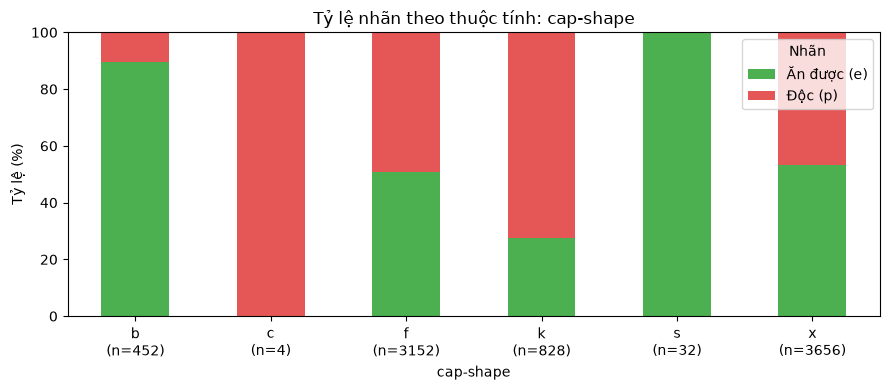

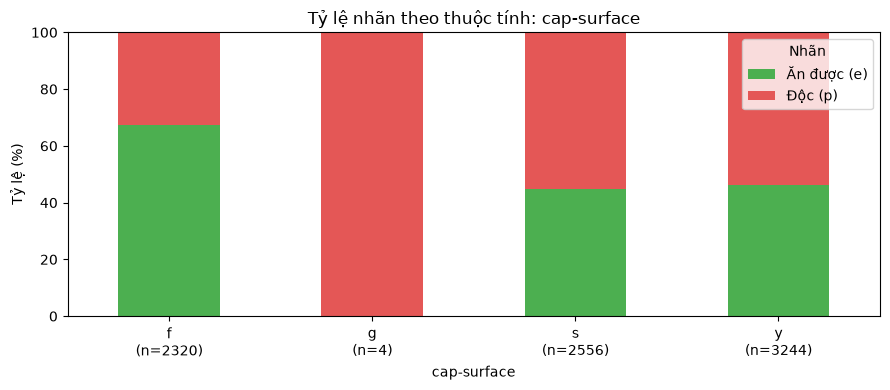

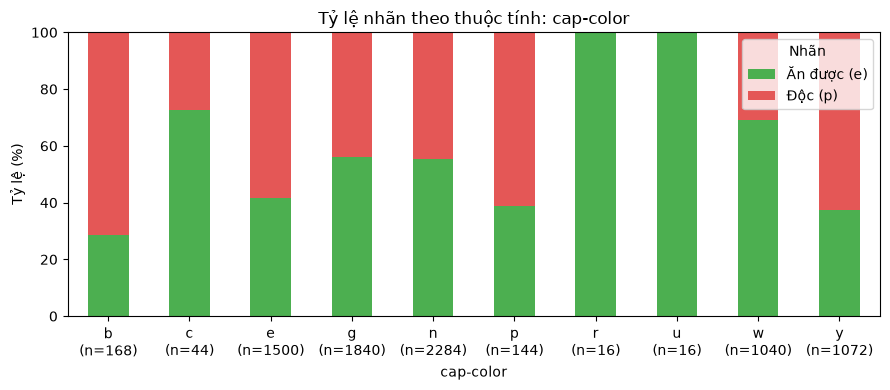

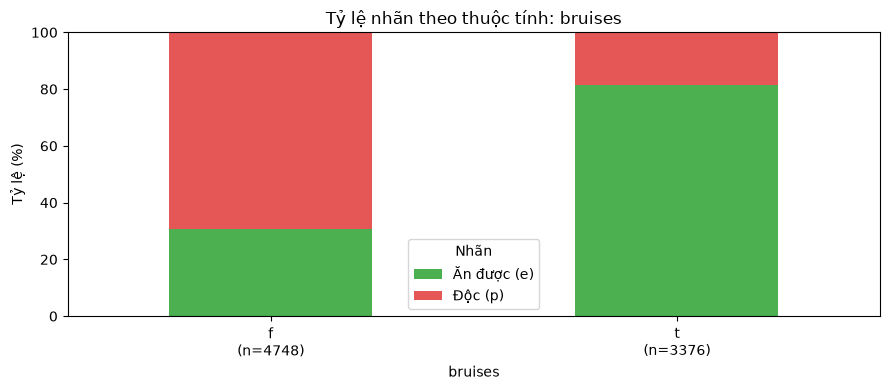

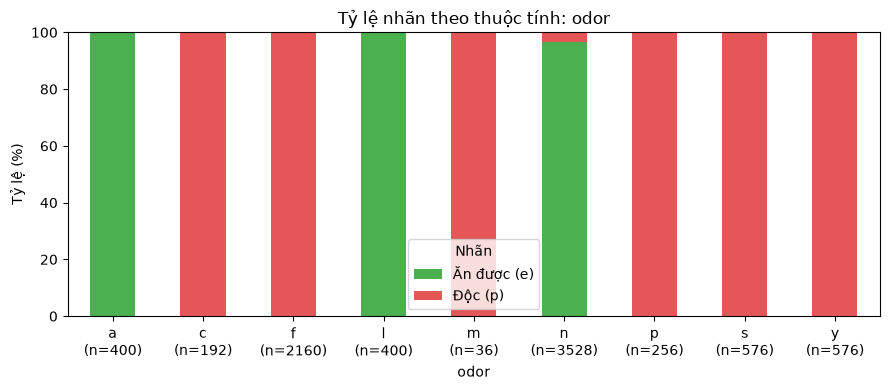

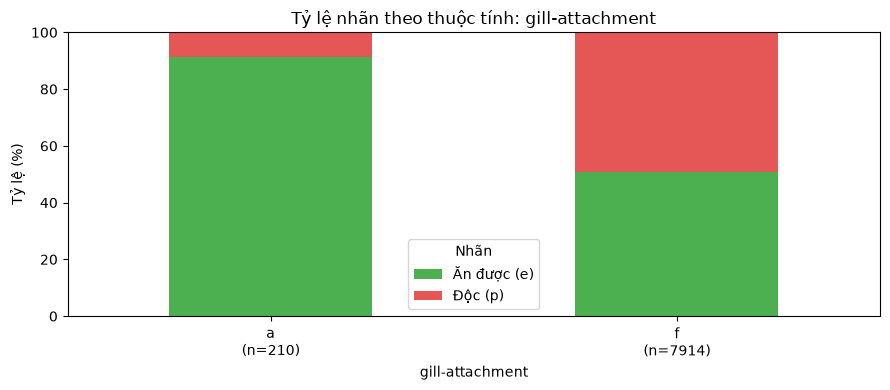

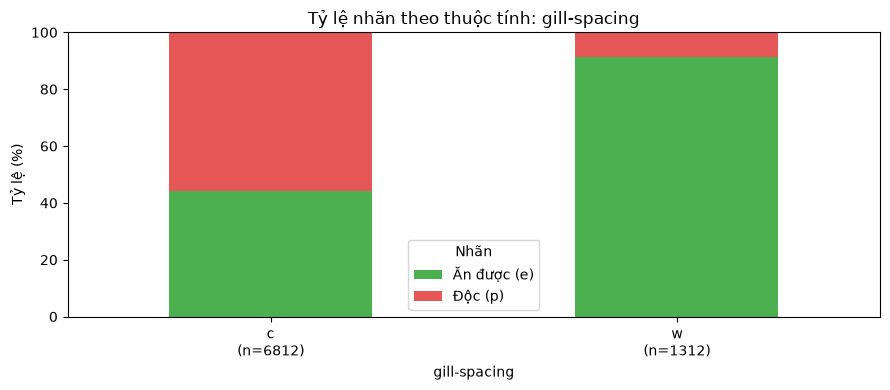

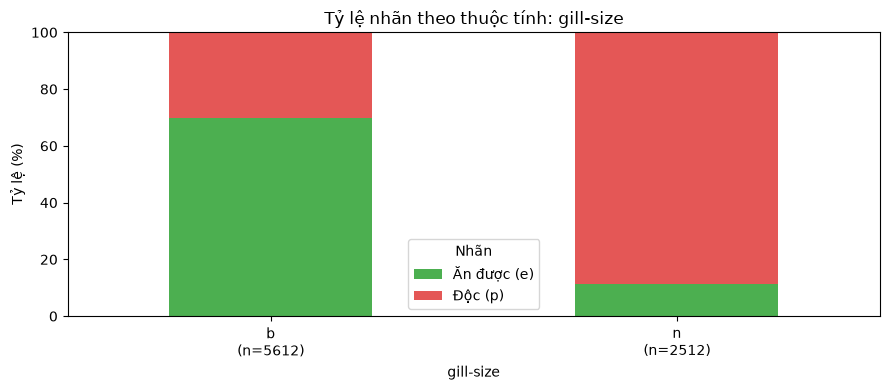

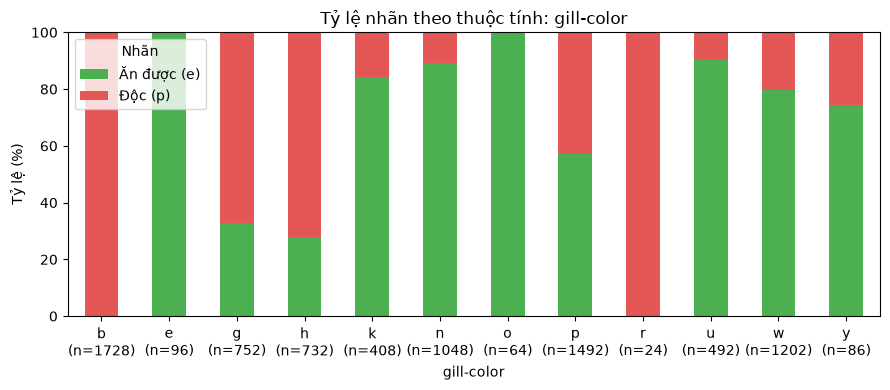

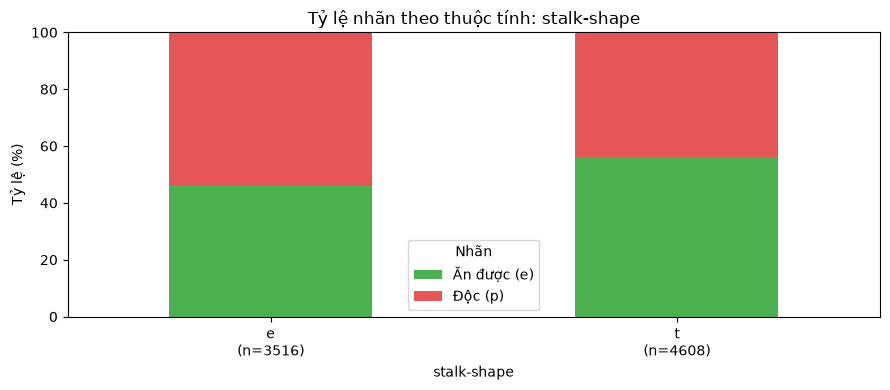

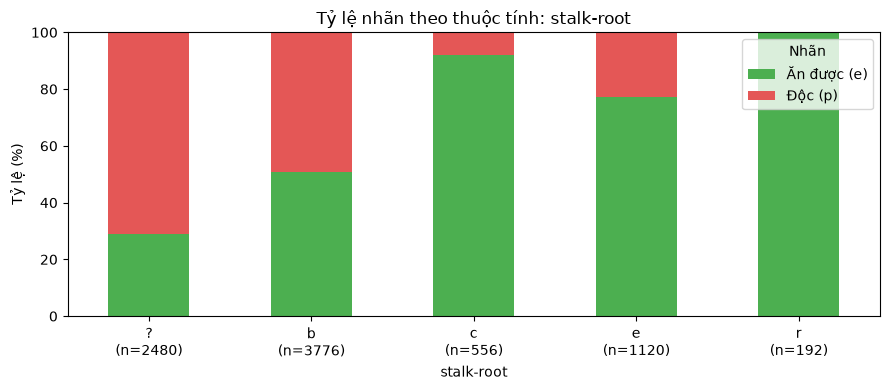

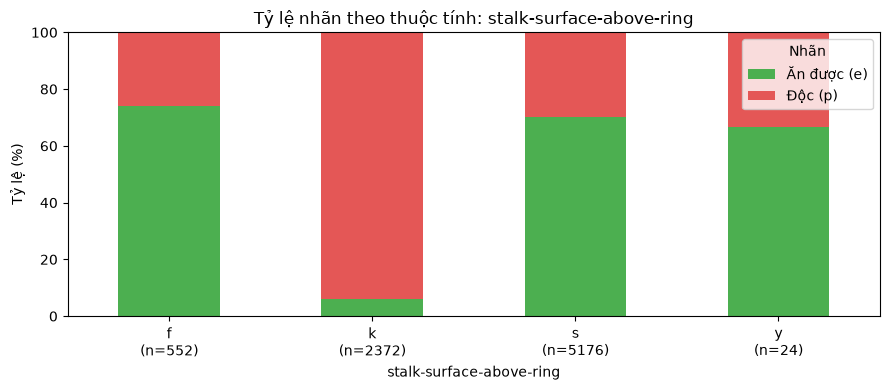

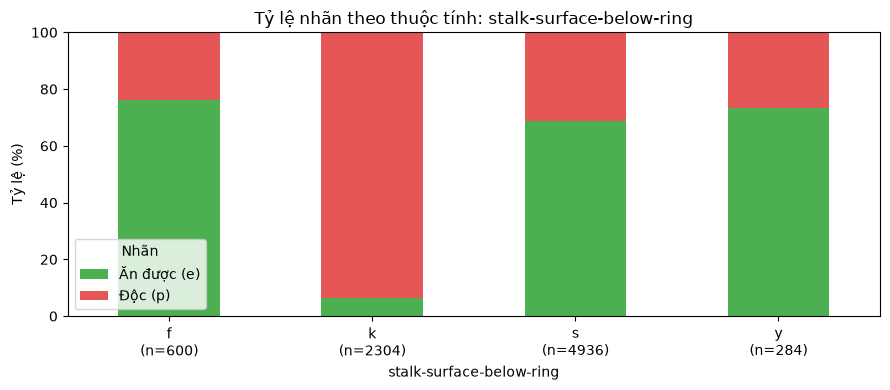

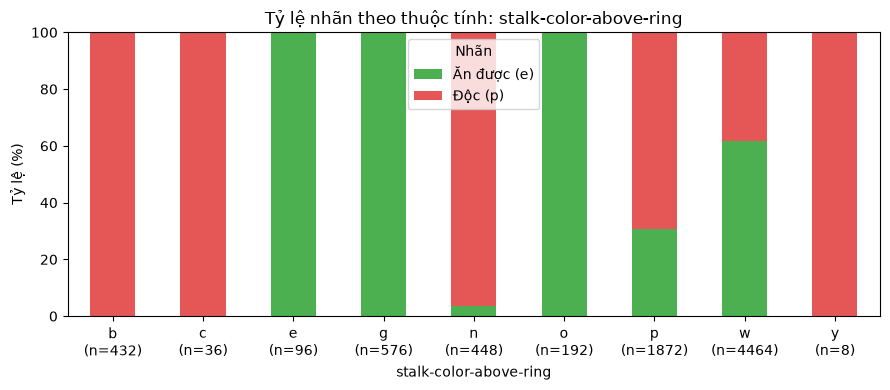

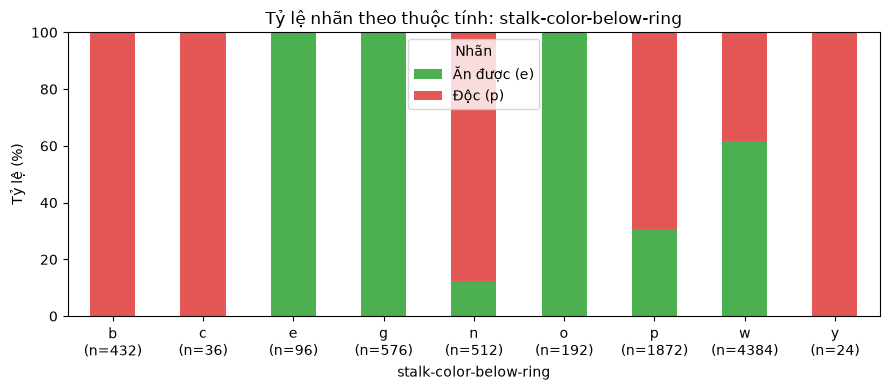

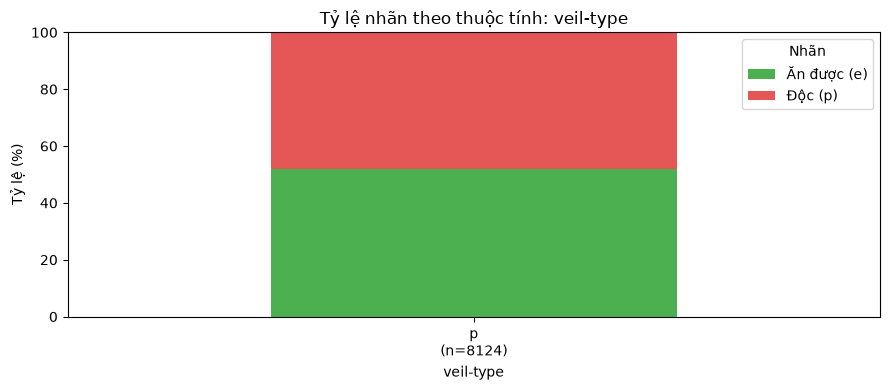

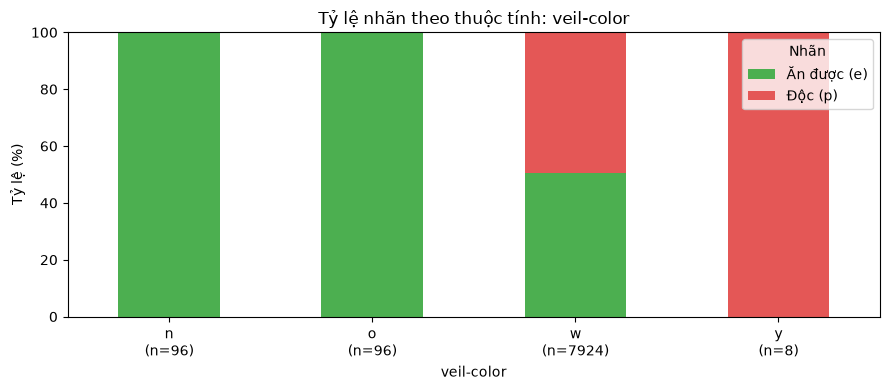

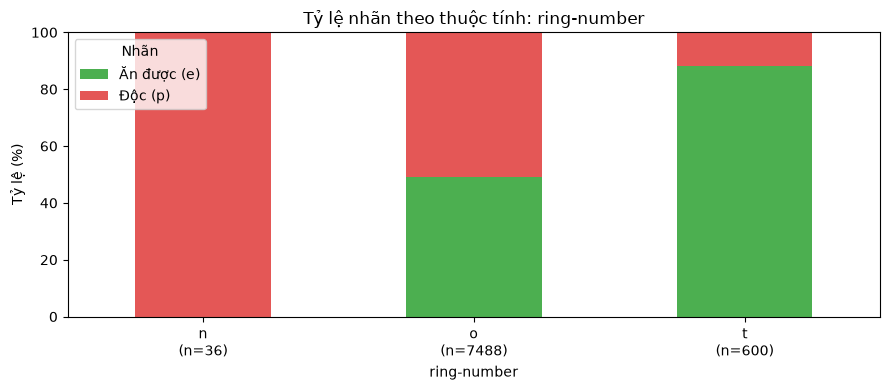

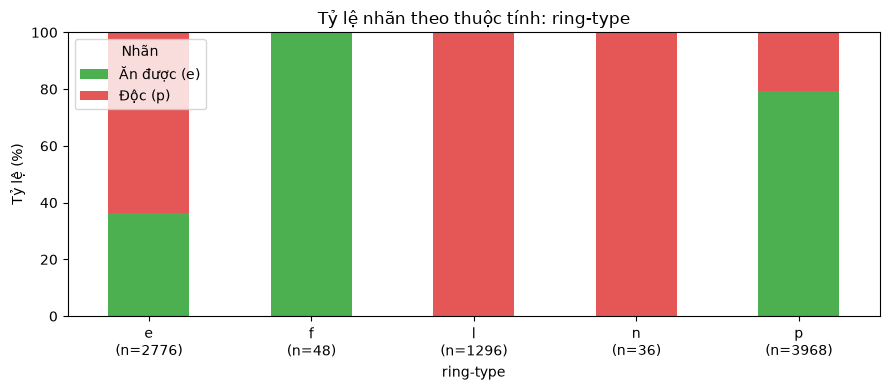

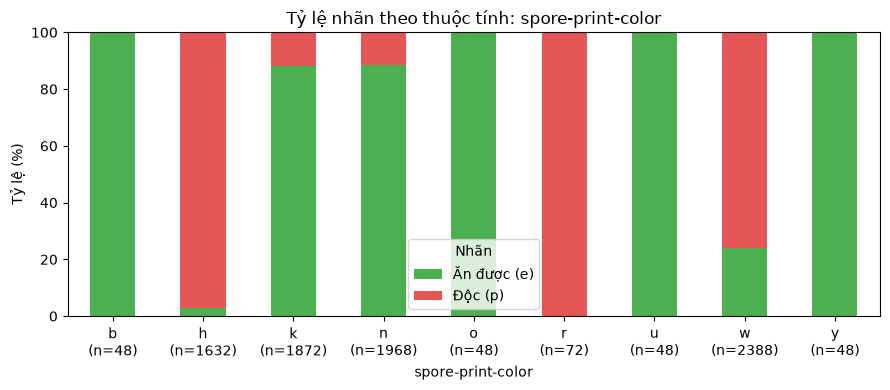

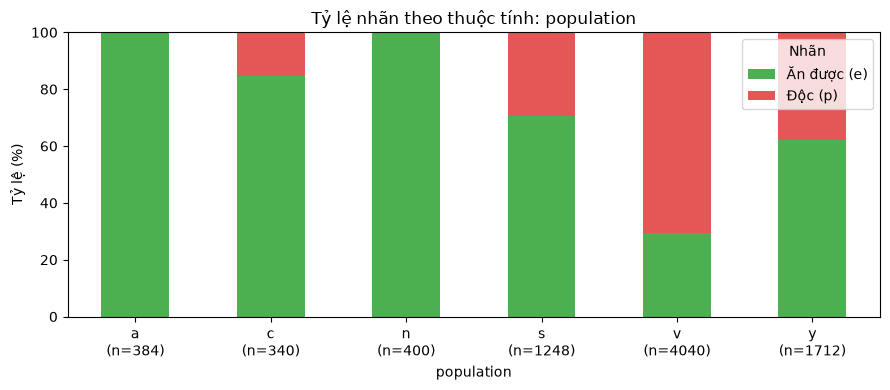

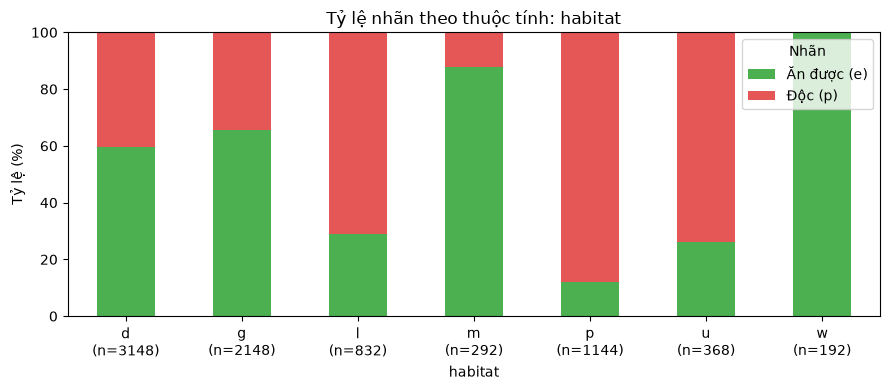

Đã lưu các biểu đồ vào: C:\Users\hauth\OneDrive\Tài liệu\GitHub\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\BÀI TẬP NHÓM HẰNG TUẦN\LAB5 BÀI TOÁN PHÂN LỚP (NHÓM)\THUẬT TOÁN PHÂN LỚP\2.3.4 Naive mushroom\data\bieu_do_thuoc_tinh


In [11]:
from pathlib import Path
import re

import matplotlib.pyplot as plt

thu_muc_anh = Path("data/bieu_do_thuoc_tinh")
thu_muc_anh.mkdir(parents=True, exist_ok=True)

if "class" not in df.columns:
	print("Không tìm thấy cột 'class' trong dataset.")
else:
	thuoc_tinh = [cot for cot in df.columns if cot != "class"]

	for cot in thuoc_tinh:
		bang_dem = pd.crosstab(df[cot], df["class"]).reindex(
			columns=["e", "p"], fill_value=0
		)

		bang_ty_le = bang_dem.div(bang_dem.sum(axis=1), axis=0) * 100
		nhan_x = [
			f"{gia_tri}\n(n={tong})"
			for gia_tri, tong in zip(bang_dem.index, bang_dem.sum(axis=1))
		]

		ax = bang_ty_le.plot(
			kind="bar",
			stacked=True,
			figsize=(9, 4),
			color=["#4CAF50", "#E45756"]
		)

		ax.set_title(f"Tỷ lệ nhãn theo thuộc tính: {cot}")
		ax.set_xlabel(cot)
		ax.set_ylabel("Tỷ lệ (%)")
		ax.set_xticklabels(nhan_x, rotation=0)
		ax.legend(title="Nhãn", labels=["Ăn được (e)", "Độc (p)"])
		ax.set_ylim(0, 100)

		fig = ax.figure
		fig.tight_layout()

		ten_file = re.sub(r'[<>:"/\\|?*]', "_", str(cot))
		fig.savefig(thu_muc_anh / f"{ten_file}.png", dpi=150, bbox_inches="tight")

		plt.show()
		plt.close(fig)

	print(f"Đã lưu các biểu đồ vào: {thu_muc_anh.resolve()}")

- So sánh theo nhãn

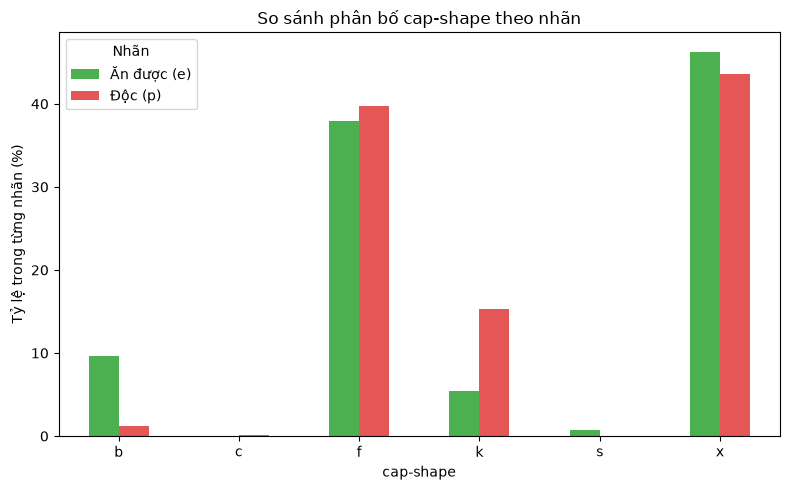

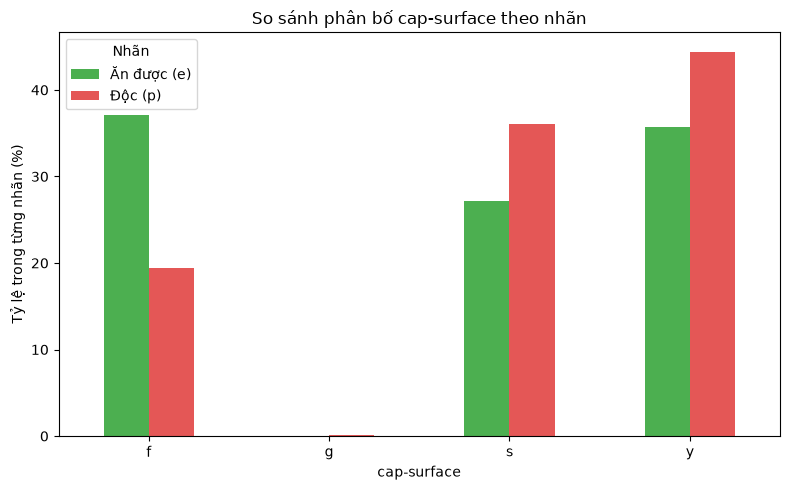

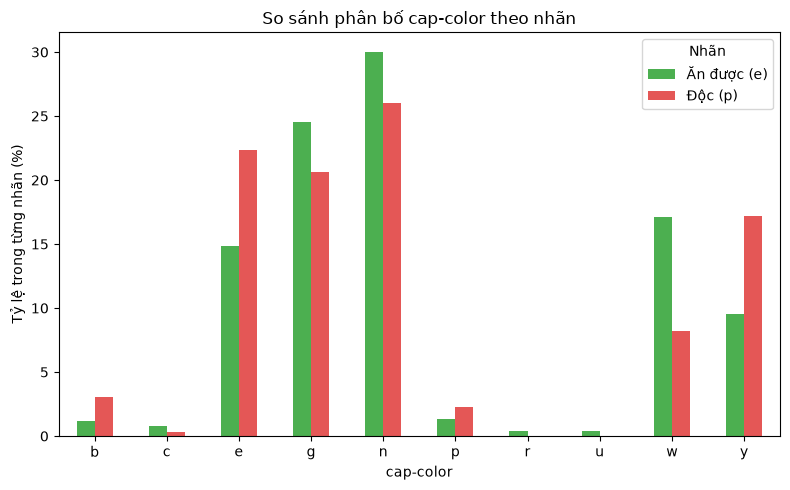

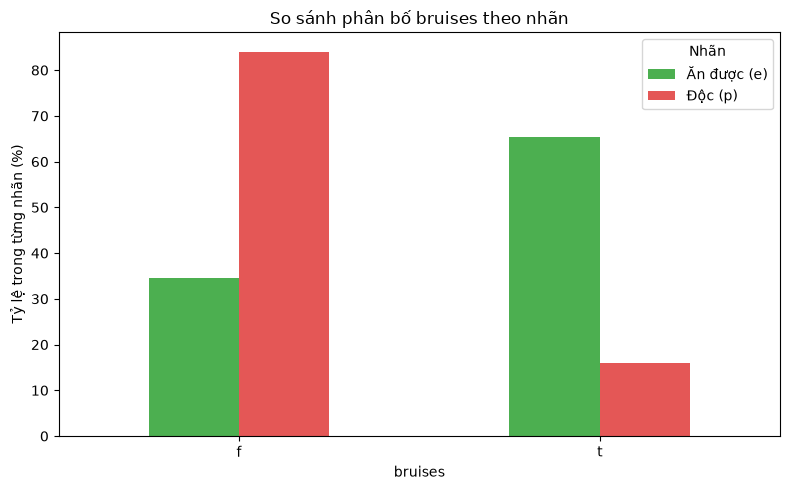

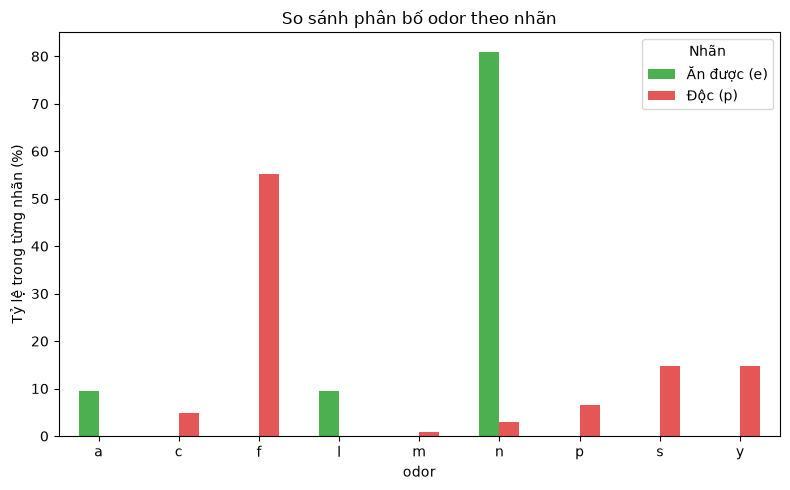

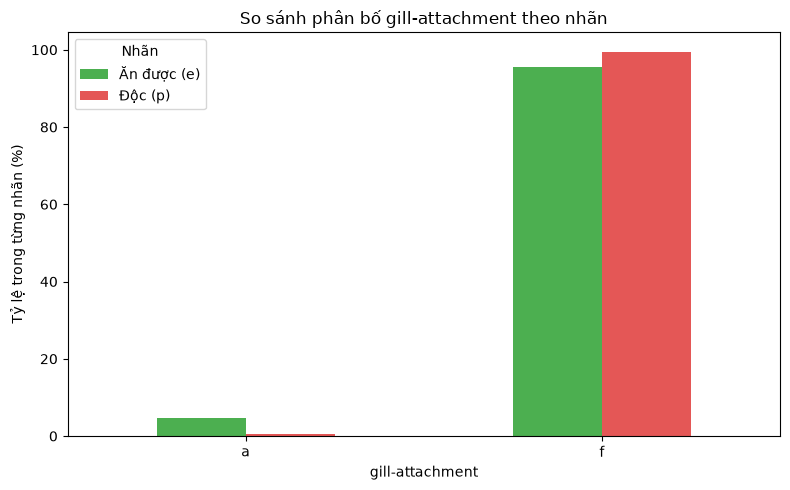

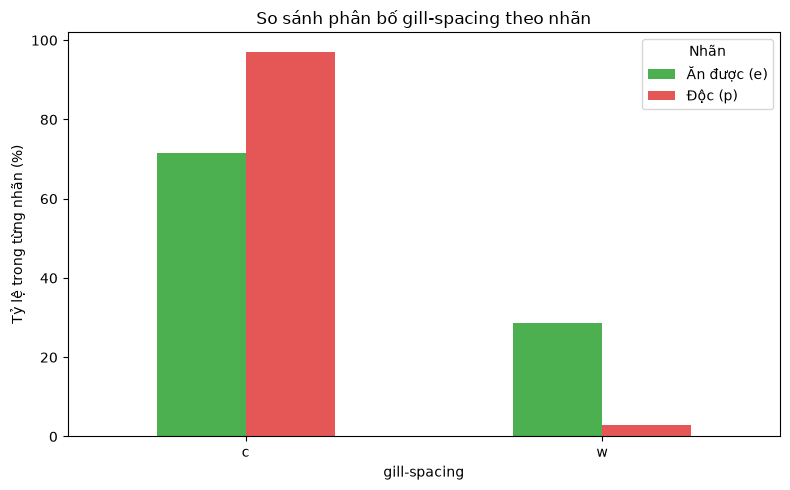

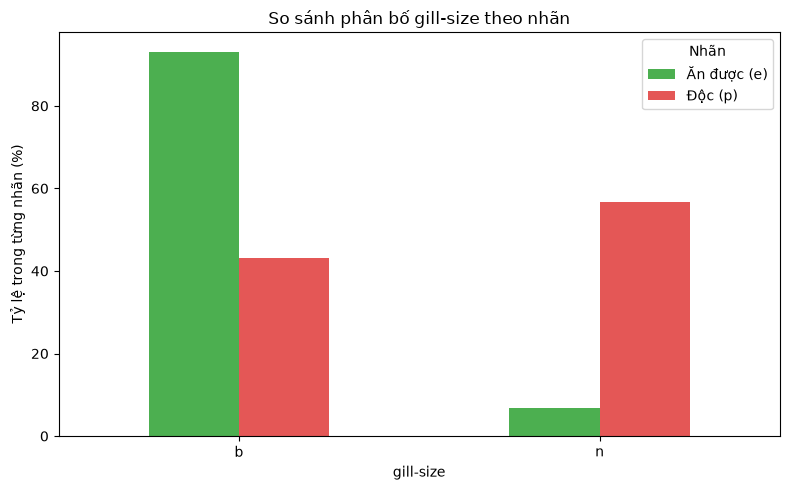

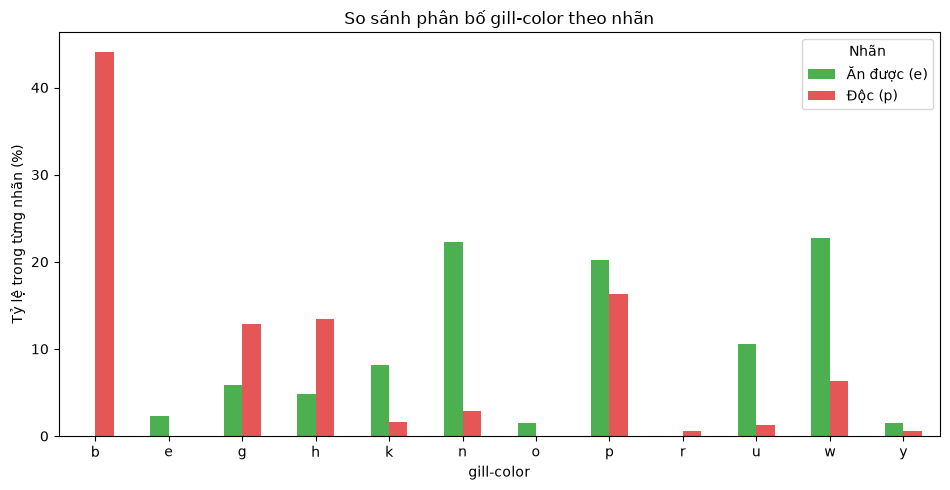

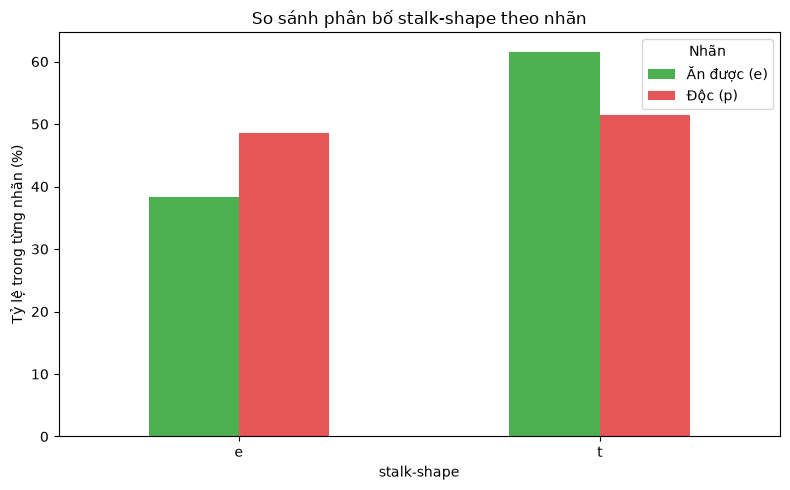

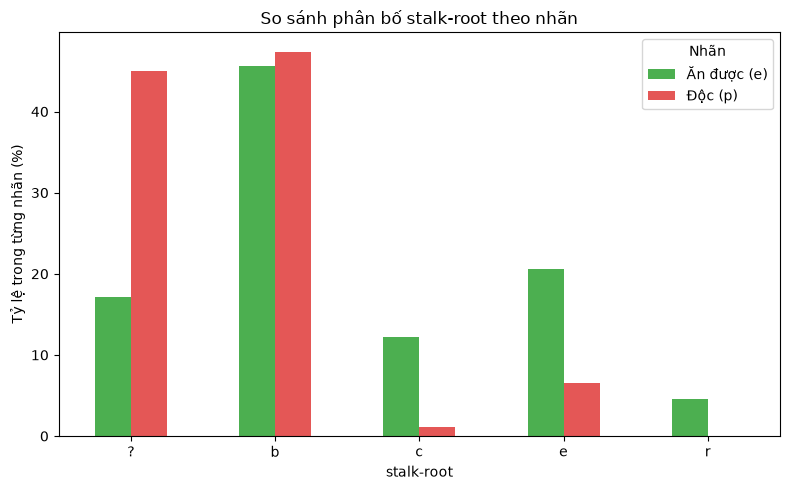

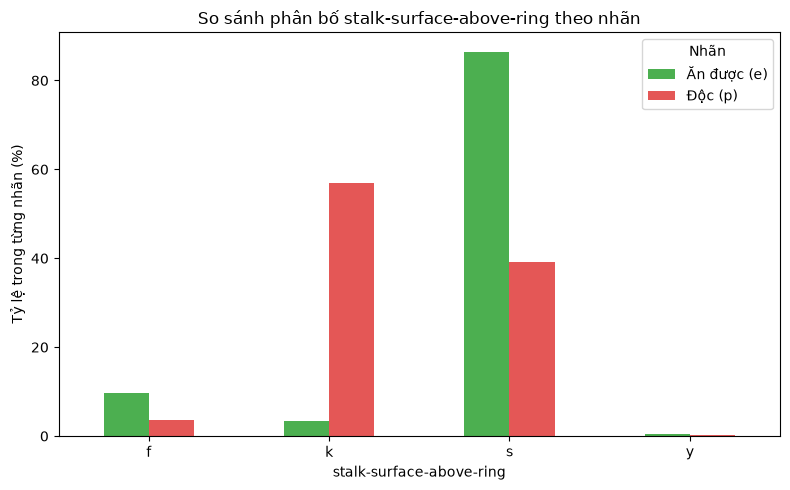

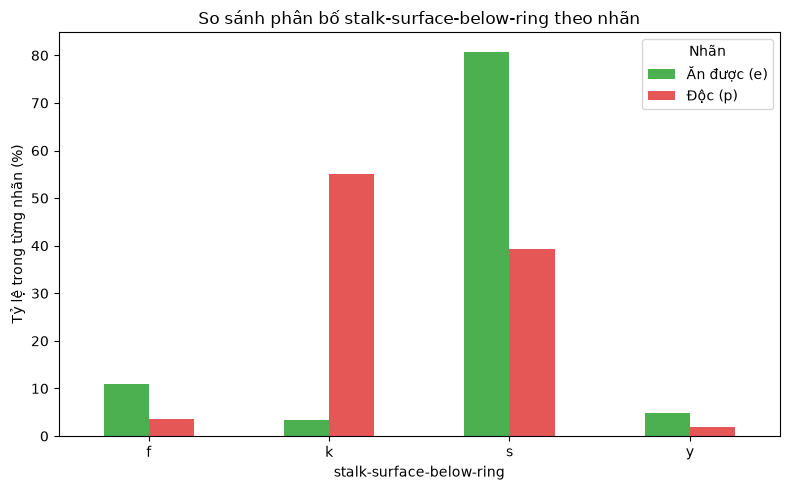

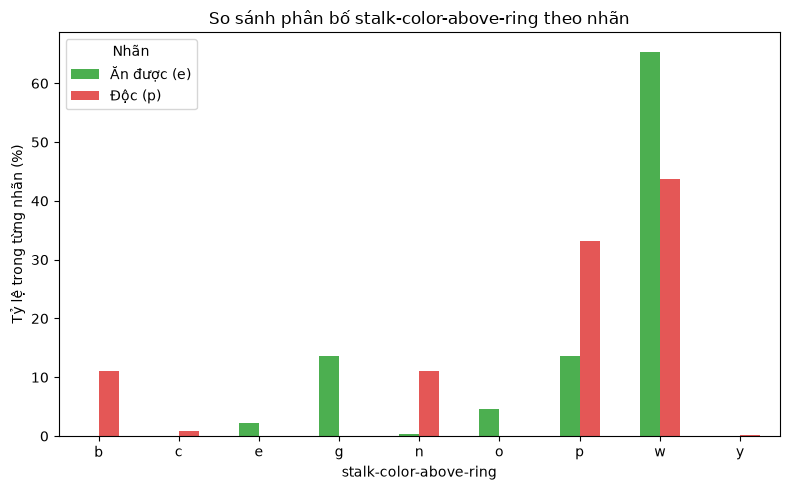

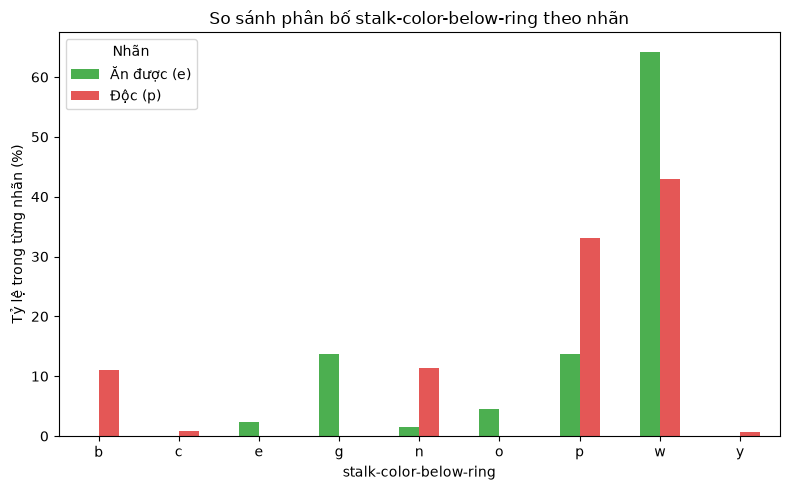

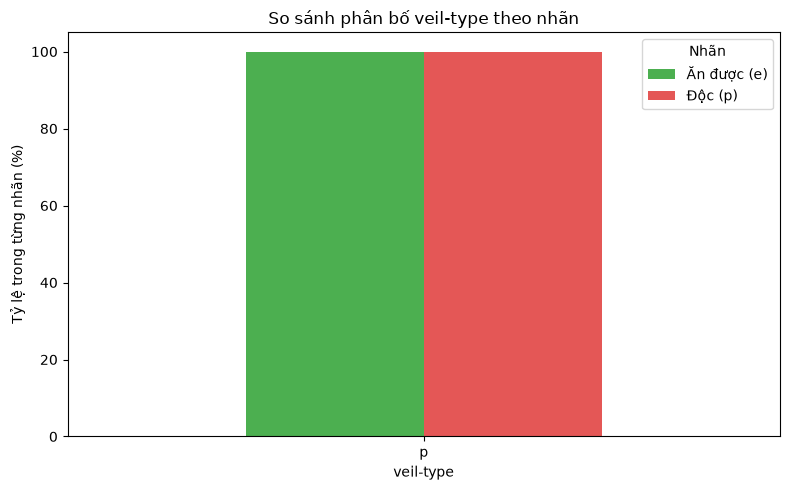

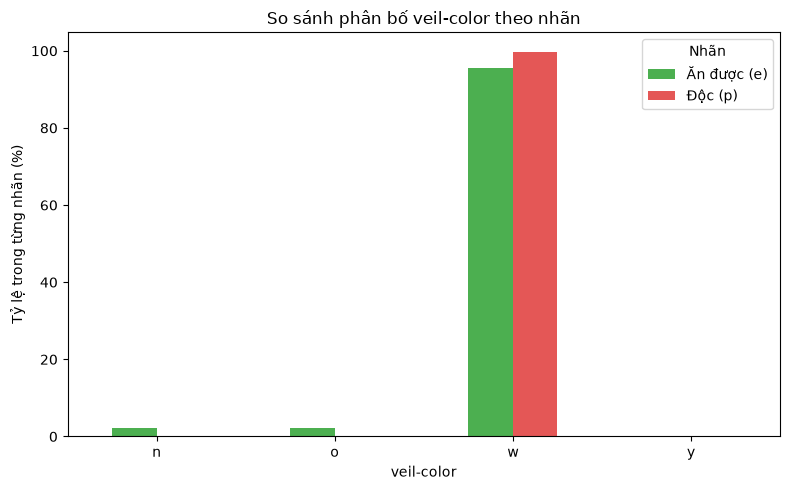

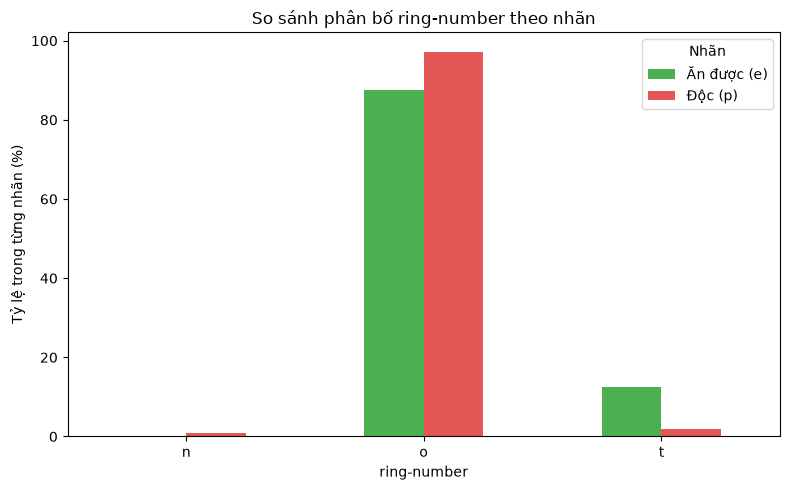

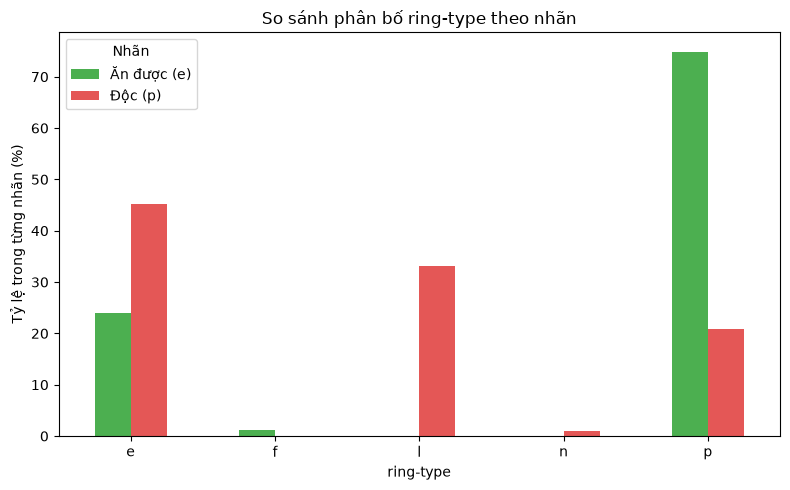

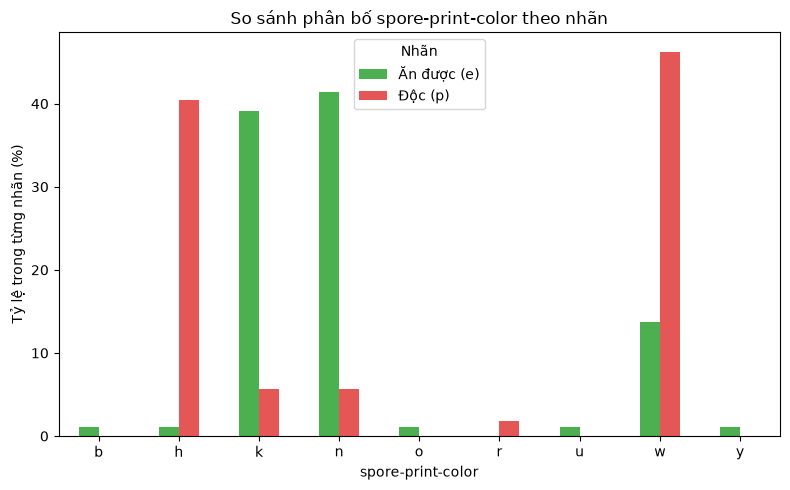

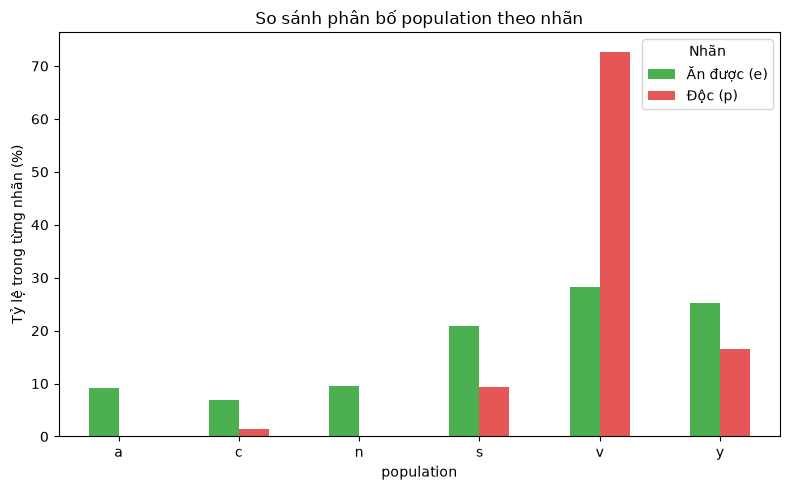

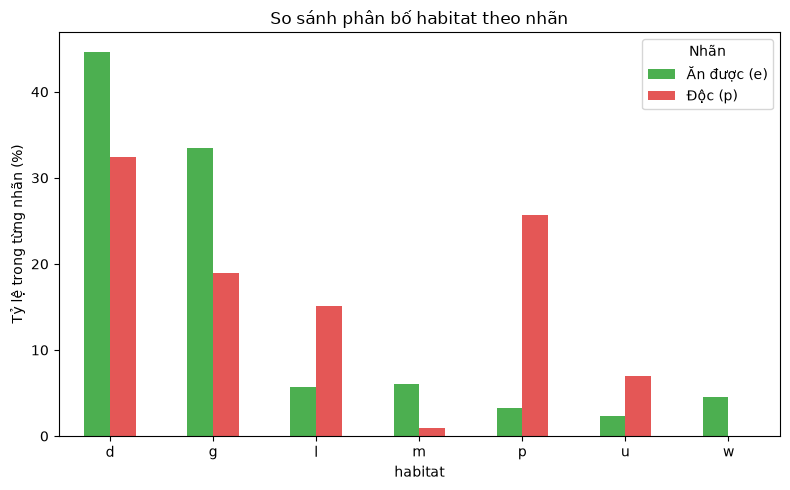

Đã lưu biểu đồ vào: C:\Users\hauth\OneDrive\Tài liệu\GitHub\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\BÀI TẬP NHÓM HẰNG TUẦN\LAB5 BÀI TOÁN PHÂN LỚP (NHÓM)\THUẬT TOÁN PHÂN LỚP\2.3.4 Naive mushroom\data\so_sanh_thuoc_tinh_theo_nhan


In [12]:
thu_muc_so_sanh = Path("data/so_sanh_thuoc_tinh_theo_nhan")
thu_muc_so_sanh.mkdir(parents=True, exist_ok=True)

if "class" not in df.columns:
	print("Không tìm thấy cột 'class' trong dataset.")
else:
	for cot in df.columns:
		if cot == "class":
			continue

		bang_ty_le_nhan = pd.crosstab(
			df[cot].fillna("NaN"),
			df["class"],
			normalize="columns"
		).reindex(columns=["e", "p"], fill_value=0) * 100

		ax = bang_ty_le_nhan.plot(
			kind="bar",
			figsize=(max(8, len(bang_ty_le_nhan) * 0.8), 5),
			color=["#4CAF50", "#E45756"]
		)

		ax.set_title(f"So sánh phân bố {cot} theo nhãn")
		ax.set_xlabel(cot)
		ax.set_ylabel("Tỷ lệ trong từng nhãn (%)")
		ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
		ax.legend(title="Nhãn", labels=["Ăn được (e)", "Độc (p)"])

		fig = ax.figure
		fig.tight_layout()

		ten_file = re.sub(r'[<>:"/\\|?*]', "_", str(cot))
		fig.savefig(
			thu_muc_so_sanh / f"{ten_file}.png",
			dpi=150,
			bbox_inches="tight"
		)
		plt.show()
		plt.close(fig)

	print(f"Đã lưu biểu đồ vào: {thu_muc_so_sanh.resolve()}")

- Phân tích mối liên hệ

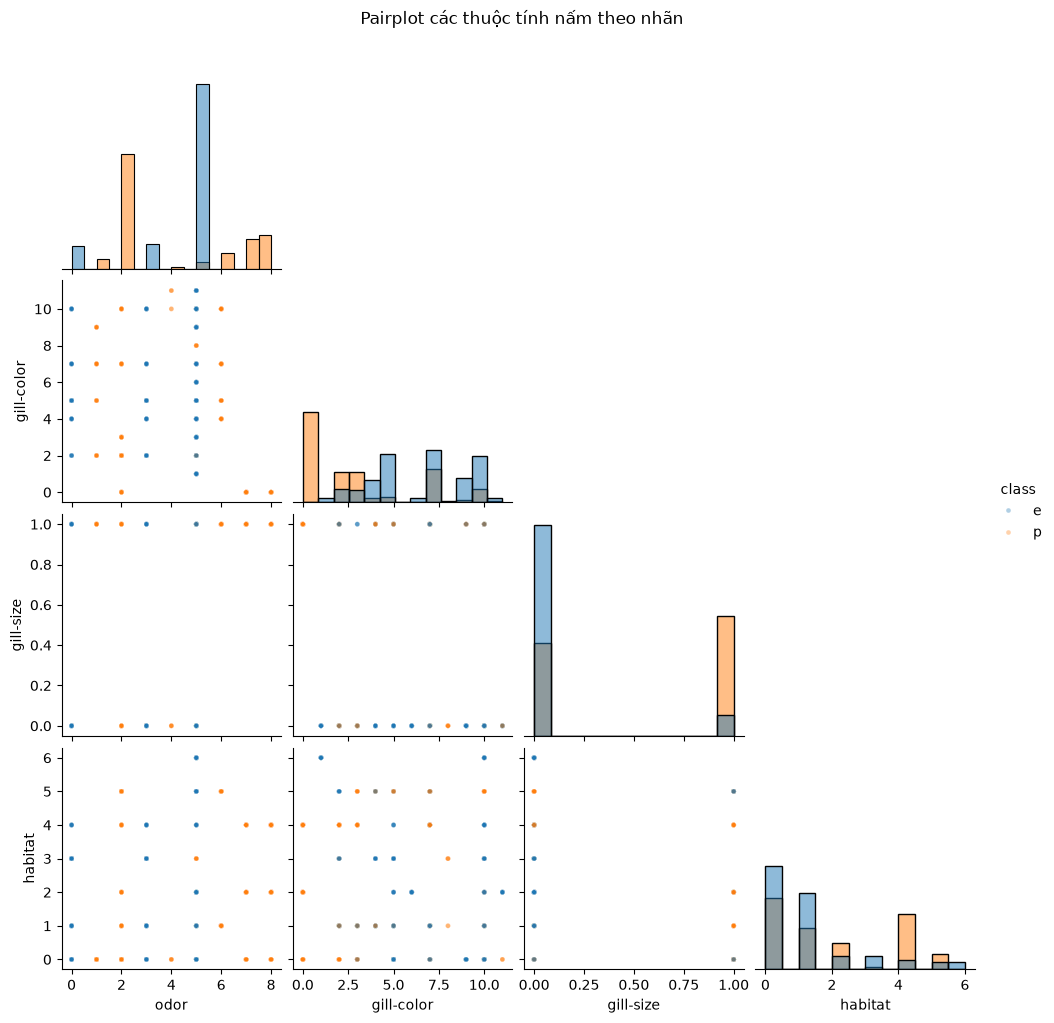

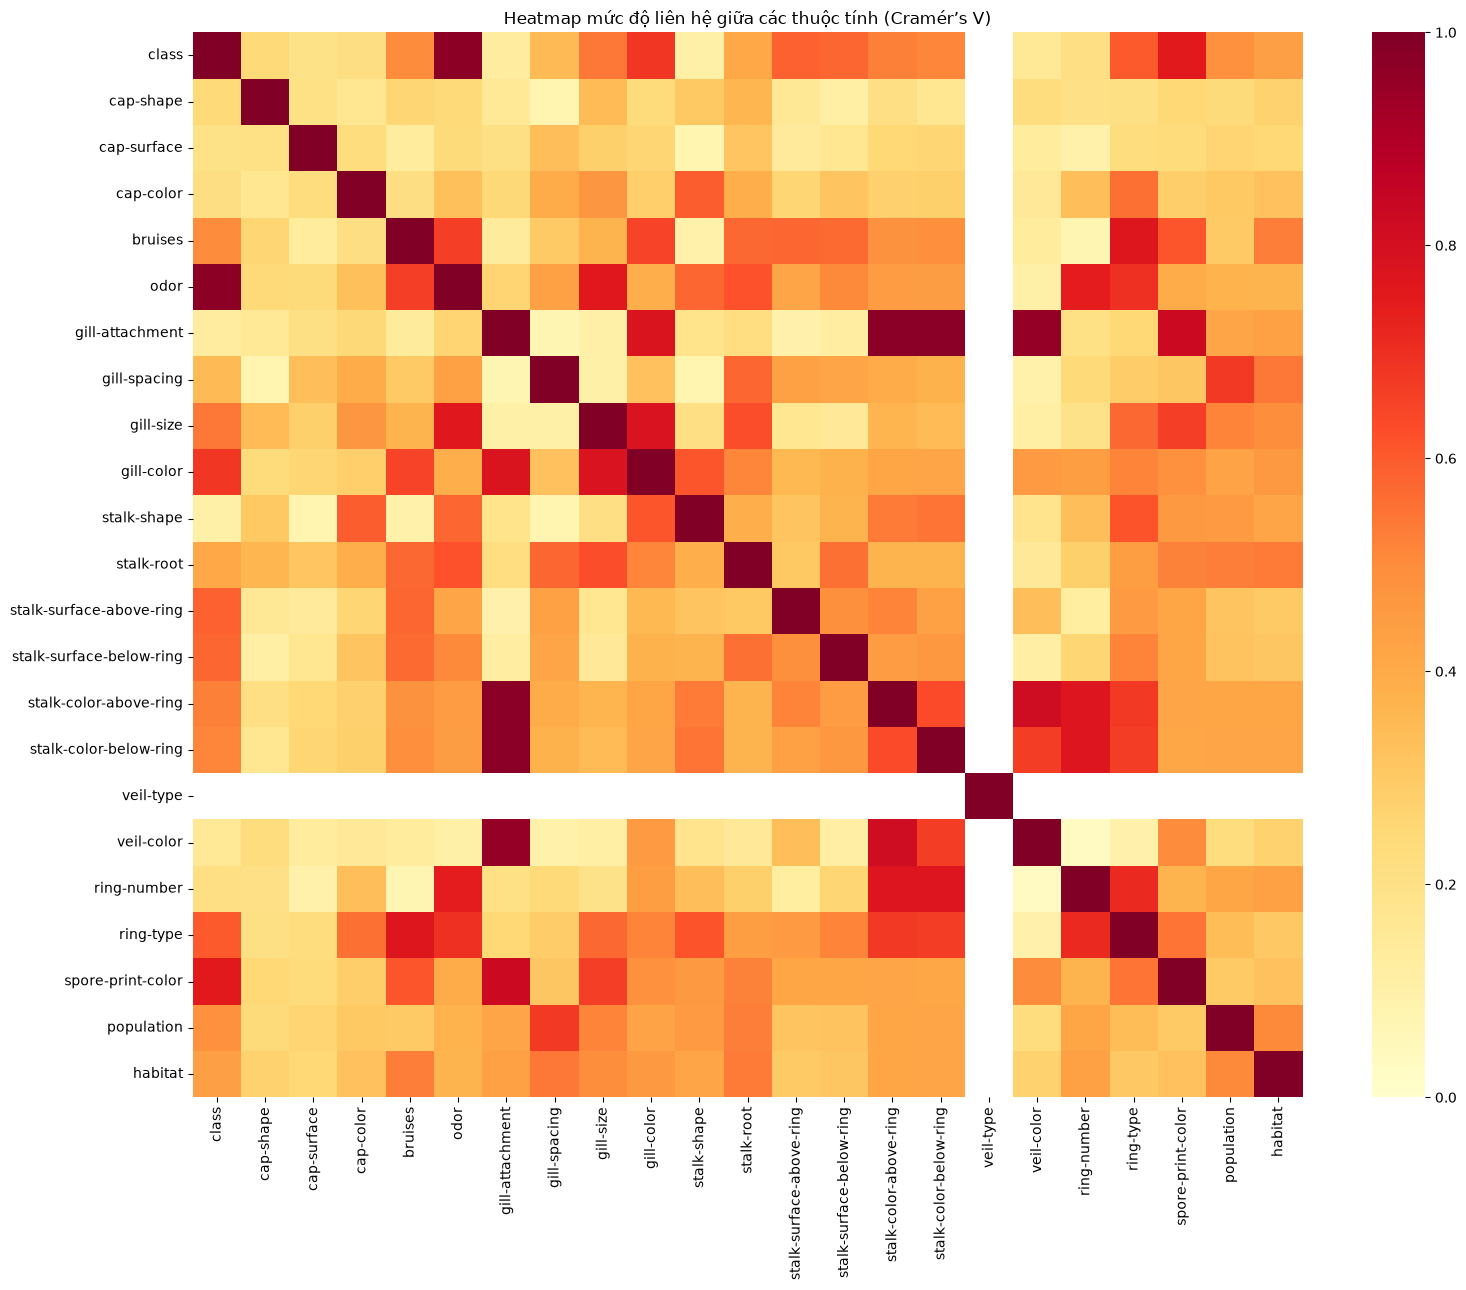

In [15]:
import numpy as np
from scipy.stats import chi2_contingency

# Pairplot: chọn một số thuộc tính để biểu đồ dễ đọc hơn
cot_pairplot = ["odor", "gill-color", "gill-size", "habitat"]
du_lieu_pairplot = df[cot_pairplot + ["class"]].copy()

for cot in cot_pairplot:
    du_lieu_pairplot[cot] = du_lieu_pairplot[cot].astype("category").cat.codes

sns.pairplot(
    du_lieu_pairplot.sample(min(1500, len(du_lieu_pairplot)), random_state=42),
    vars=cot_pairplot,
    hue="class",
    corner=True,
    diag_kind="hist",
    plot_kws={"alpha": 0.35, "s": 12}
)
plt.suptitle("Pairplot các thuộc tính nấm theo nhãn", y=1.02)
plt.show()

# Tính ma trận Cramér's V cho các thuộc tính
def tinh_cramers_v(x, y):
    bang_cheo = pd.crosstab(x.fillna("NaN"), y.fillna("NaN"))
    if min(bang_cheo.shape) < 2:
        return np.nan

    chi2 = chi2_contingency(bang_cheo, correction=False)[0]
    n = bang_cheo.to_numpy().sum()
    return np.sqrt(chi2 / (n * min(bang_cheo.shape[0] - 1, bang_cheo.shape[1] - 1)))

cot_phan_tich = df.columns
ma_tran_cramers_v = pd.DataFrame(
    np.eye(len(cot_phan_tich)),
    index=cot_phan_tich,
    columns=cot_phan_tich
)

for i, cot_1 in enumerate(cot_phan_tich):
    for cot_2 in cot_phan_tich[i + 1:]:
        gia_tri = tinh_cramers_v(df[cot_1], df[cot_2])
        ma_tran_cramers_v.loc[cot_1, cot_2] = gia_tri
        ma_tran_cramers_v.loc[cot_2, cot_1] = gia_tri

plt.figure(figsize=(16, 13))
sns.heatmap(
    ma_tran_cramers_v,
    cmap="YlOrRd",
    vmin=0,
    vmax=1
)
plt.title("Heatmap mức độ liên hệ giữa các thuộc tính (Cramér’s V)")
plt.tight_layout()
plt.show()